# 03 — Data Modelling
## OSMI 2016: Workplace Support, Psychological Safety, and Disclosure Climate

### Objective
Fit and compare four pre-specified unsupervised clustering families on the 1,131-respondent eligible cohort: **K-Modes**, **MCA + K-Means**, **average-linkage agglomerative clustering**, and **HDBSCAN**.

This notebook consumes the persisted outputs from Notebook 02. It does not redefine the cohort, change the 15 primary features, or use demographic, health-history, diagnosis, treatment, geographic, or free-text variables as clustering inputs.

### Modelling contract
- K-Modes uses categorical labels and simple matching dissimilarity.
- MCA + K-Means uses row principal coordinates derived from the complete disjunctive matrix.
- Agglomerative clustering uses average linkage on the supplied precomputed domain-balanced Gower dissimilarities. Ward linkage is not valid for this precomputed dissimilarity.
- HDBSCAN uses the same precomputed Gower dissimilarities; noise is reported explicitly.
- A common Gower silhouette is a supplementary cross-family diagnostic, not a universal ranking criterion. Native diagnostics remain method-specific.
- Repeated-start ARI measures optimisation stability only; it is not resampling or population stability.
- This notebook selects one representative configuration **within each family**. Final model-family selection is deferred to Notebook 04.

The data are historical, voluntary and self-reported. Clusters describe aggregate workplace-response patterns; they are not clinical labels or employee-risk classifications.

## 1. Imports, reproducibility, and project paths

In [21]:
from __future__ import annotations

import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from hdbscan import HDBSCAN
from hdbscan.validity import validity_index
from kmodes.kmodes import KModes
from scipy.cluster.hierarchy import cophenet, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

RANDOM_STATE = 42
N_REPEATS = 10
K_VALUES = range(2, 9)
SILHOUETTE_SAMPLE_SIZE = 600
SILHOUETTE_SEED = 42

# Resolve the project root whether this notebook is opened from the repository
# root or from its notebooks/ directory.
HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name == "notebooks" else HERE
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results" / "data_modelling"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "data_modelling"
for directory in (RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

## 2. Load and validate Notebook 02 artefacts

In [13]:
INPUT_FILES = {
    "kmodes": PROCESSED_DIR / "osmi_2016_kmodes_input.csv",
    "mca_indicator": PROCESSED_DIR / "osmi_2016_mca_indicator_matrix.csv",
    "gower_typed": PROCESSED_DIR / "osmi_2016_gower_typed_input.csv",
    "gower": PROCESSED_DIR / "osmi_2016_gower_dissimilarity.npy",
    "row_mapping": PROCESSED_DIR / "osmi_2016_model_row_mapping.csv",
    "feature_metadata": PROCESSED_DIR / "osmi_2016_feature_metadata.csv",
    "preparation_metadata": PROCESSED_DIR / "osmi_2016_preparation_metadata.json",
}
missing_files = [str(path) for path in INPUT_FILES.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Notebook 02 artefacts are missing. Run Notebook 02 first. Missing: "
        + ", ".join(missing_files)
    )

X_kmodes = pd.read_csv(INPUT_FILES["kmodes"], dtype="string")
X_mca_indicator = pd.read_csv(INPUT_FILES["mca_indicator"])
X_gower_typed = pd.read_csv(INPUT_FILES["gower_typed"], dtype="string")
D_gower = np.load(INPUT_FILES["gower"], allow_pickle=False)
row_mapping = pd.read_csv(INPUT_FILES["row_mapping"])
feature_metadata = pd.read_csv(INPUT_FILES["feature_metadata"])

with INPUT_FILES["preparation_metadata"].open(encoding="utf-8") as file:
    preparation_metadata = json.load(file)

PRIMARY_FEATURES = preparation_metadata["primary_features"]
FEATURES_BY_DOMAIN = preparation_metadata["feature_domains"]
EXPECTED_N = int(preparation_metadata["eligible_cohort_size"])
EXPECTED_P = int(preparation_metadata["primary_feature_count"])

assert EXPECTED_N == 1131, f"Expected 1,131 respondents; found {EXPECTED_N}."
assert EXPECTED_P == 15 and len(PRIMARY_FEATURES) == 15
assert X_kmodes.shape == (EXPECTED_N, EXPECTED_P)
assert X_gower_typed.shape == (EXPECTED_N, EXPECTED_P)
assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert list(X_gower_typed.columns) == PRIMARY_FEATURES
assert X_mca_indicator.shape[0] == EXPECTED_N
assert len(row_mapping) == EXPECTED_N
assert row_mapping["model_row_index"].is_unique
assert np.array_equal(row_mapping["model_row_index"].to_numpy(), np.arange(EXPECTED_N))
assert D_gower.shape == (EXPECTED_N, EXPECTED_N)
assert np.isfinite(D_gower).all()
assert np.allclose(D_gower, D_gower.T, atol=1e-7)
assert np.allclose(np.diag(D_gower), 0.0, atol=1e-7)
assert D_gower.min() >= -1e-7 and D_gower.max() <= 1 + 1e-7
assert not X_kmodes.isna().any().any()
assert not X_gower_typed.isna().any().any()
assert not X_mca_indicator.isna().any().any()

excluded = {
    "gender",
    "age",
    "country_live",
    "country_work",
    "us_state_live",
    "us_state_work",
    "company_size",
    "work_remote",
    "self_employed",
    "tech_company",
    "tech_role",
    "source_row_position",
}

for matrix in (X_kmodes, X_gower_typed, X_mca_indicator):
    assert not excluded.intersection(matrix.columns)

domain_summary = pd.DataFrame({
    "domain": list(FEATURES_BY_DOMAIN),
    "features": [len(v) for v in FEATURES_BY_DOMAIN.values()],
    "domain_weight": [1 / len(FEATURES_BY_DOMAIN)] * len(FEATURES_BY_DOMAIN),
})

display(domain_summary)
print(f"Validated {EXPECTED_N:,} respondents × {EXPECTED_P} primary features.")
print(f"Gower matrix: {D_gower.shape}, dtype={D_gower.dtype}, "
      f"range=[{D_gower.min():.3f}, {D_gower.max():.3f}]")

,domain,features,domain_weight
0,employer_support,6,0.333333
1,psychological_safety,5,0.333333
2,disclosure_career_climate,4,0.333333


Validated 1,131 respondents × 15 primary features.
Gower matrix: (1131, 1131), dtype=float32, range=[0.000, 1.000]


## 3. Shared evaluation functions

The common Gower silhouette is computed on a deterministic sample of at most 600 non-noise observations. This limits the cost of repeated silhouette calculations while keeping the sample fixed across candidate partitions. For HDBSCAN, noise observations are excluded from the silhouette but remain included in coverage and noise reporting.

A silhouette is undefined when fewer than two clusters or as many clusters as observations remain in the evaluated subset; those cases are recorded as missing rather than coerced into a score.

In [5]:
def cluster_summary(labels: np.ndarray) -> dict:
    labels = np.asarray(labels)
    non_noise = labels != -1
    assigned = labels[non_noise]
    unique = np.unique(assigned)
    counts = pd.Series(assigned).value_counts()
    return {
        "n_clusters": int(len(unique)),
        "n_noise": int((~non_noise).sum()),
        "noise_share": float((~non_noise).mean()),
        "coverage": float(non_noise.mean()),
        "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
        "median_cluster_size": float(counts.median()) if len(counts) else 0.0,
        "max_cluster_size": int(counts.max()) if len(counts) else 0,
    }


def common_gower_silhouette(
    labels: np.ndarray,
    sample_size=SILHOUETTE_SAMPLE_SIZE
) -> float:
    labels = np.asarray(labels)
    eligible = np.flatnonzero(labels != -1)
    if len(eligible) < 3 or len(np.unique(labels[eligible])) < 2:
        return np.nan
    rng = np.random.default_rng(SILHOUETTE_SEED)
    if len(eligible) > sample_size:
        selected = np.sort(rng.choice(
            eligible, size=sample_size, replace=False
        ))
    else:
        selected = eligible
    y = labels[selected]
    if len(np.unique(y)) < 2 or len(np.unique(y)) >= len(y):
        return np.nan
    return float(silhouette_score(
        D_gower[np.ix_(selected, selected)], y, metric="precomputed"
    ))


def pairwise_mean_ari(label_runs: list[np.ndarray]) -> float:
    if len(label_runs) < 2:
        return np.nan
    scores = [
        adjusted_rand_score(a, b)
        for a, b in combinations(label_runs, 2)
    ]
    return float(np.mean(scores))


def mca_silhouette(coordinates: np.ndarray, labels: np.ndarray,
                   sample_size=SILHOUETTE_SAMPLE_SIZE) -> float:
    rng = np.random.default_rng(SILHOUETTE_SEED)
    idx = np.arange(len(labels))
    if len(idx) > sample_size:
        idx = np.sort(rng.choice(idx, size=sample_size, replace=False))
    y = labels[idx]
    if len(np.unique(y)) < 2 or len(np.unique(y)) >= len(y):
        return np.nan
    return float(silhouette_score(coordinates[idx], y, metric="euclidean"))

## 4. MCA: derive row principal coordinates

In [6]:
# Complete disjunctive matrix: rows are respondents; columns are observed categories.
Z = X_mca_indicator.to_numpy(dtype=np.float64)
if not np.isin(Z, [0.0, 1.0]).all():
    raise ValueError("MCA indicator matrix must contain only 0/1 values.")
if not np.all(Z.sum(axis=1) == EXPECTED_P):
    raise ValueError(
        "Each respondent must have exactly one active indicator per feature."
    )

n, q = Z.shape
P = Z / (n * EXPECTED_P)
row_masses = P.sum(axis=1)
column_masses = P.sum(axis=0)
if np.any(row_masses <= 0) or np.any(column_masses <= 0):
    raise ValueError("MCA contains zero-mass rows or columns.")

standardised_residuals = (
    (P - np.outer(row_masses, column_masses))
    / np.sqrt(row_masses[:, None] * column_masses[None, :])
)

U, singular_values, Vt = np.linalg.svd(standardised_residuals, full_matrices=False)
eigenvalues = singular_values ** 2
total_inertia = float(eigenvalues.sum())
explained_inertia = eigenvalues / total_inertia
cumulative_inertia = np.cumsum(explained_inertia)

# Retain the smallest number of dimensions reaching 80% of raw inertia,
# capped at 20 to keep the clustering space compact. This is a pragmatic
# modelling choice, not a universal MCA threshold.
n_components = min(
    int(np.searchsorted(cumulative_inertia, 0.80) + 1),
    20,
    len(singular_values),
)
mca_coordinates = (
    U[:, :n_components]
    * singular_values[:n_components][None, :]
    / np.sqrt(row_masses[:, None])
)
mca_inertia = pd.DataFrame({
    "dimension": np.arange(1, len(explained_inertia) + 1),
    "eigenvalue": eigenvalues,
    "explained_inertia_pct": explained_inertia * 100,
    "cumulative_inertia_pct": cumulative_inertia * 100,
})

display(mca_inertia.head(15))
print(
    f"MCA indicator matrix: {Z.shape}; retained dimensions: {n_components}; "
    f"cumulative raw inertia: {cumulative_inertia[n_components-1]:.1%}"
)

,dimension,eigenvalue,explained_inertia_pct,cumulative_inertia_pct
0,1,0.306666,12.432389,12.432389
1,2,0.153157,6.209063,18.641452
2,3,0.122313,4.958635,23.600087
3,4,0.103119,4.180497,27.780583
4,5,0.096852,3.926416,31.706999
5,6,0.091296,3.701188,35.408187
6,7,0.085913,3.482950,38.891138
7,8,0.084342,3.419278,42.310416
8,9,0.076793,3.113238,45.423653
9,10,0.075810,3.073371,48.497025


MCA indicator matrix: (1131, 52); retained dimensions: 20; cumulative raw inertia: 74.0%


## 5. K-Modes: categorical partitioning

In [16]:
# K-Modes clustering using the kmodes package.
# All 15 primary features are treated as categorical in this model family.
# The ordinal leave-ease feature is intentionally treated as nominal here.
# Repeated independent initialisations assess optimisation stability.

X_codes = np.column_stack([
    pd.Categorical(X_kmodes[col]).codes.astype(np.int32)
    for col in PRIMARY_FEATURES
])

if (X_codes < 0).any():
    raise ValueError(
        "Unexpected missing category code in K-Modes input."
    )


kmodes_runs = {}
kmodes_records = []

for k in K_VALUES:
    runs = []
    run_costs = []
    run_iterations = []
    run_seeds = []

    for repeat in range(N_REPEATS):
        seed = RANDOM_STATE + 1000 * k + repeat

        model = KModes(
            n_clusters=k,
            init="Huang",
            n_init=1,
            max_iter=100,
            verbose=0,
            random_state=seed,
            n_jobs=-1,
        )

        labels = model.fit_predict(X_codes).astype(np.int32)

        runs.append(labels)
        run_costs.append(float(model.cost_))
        run_iterations.append(int(model.n_iter_))
        run_seeds.append(seed)

    # Select the lowest-cost independent initialisation.
    best_index = int(np.argmin(run_costs))
    best_labels = runs[best_index]
    best_cost = run_costs[best_index]
    best_seed = run_seeds[best_index]

    kmodes_runs[k] = {
        "labels": best_labels,
        "runs": runs,
        "cost": best_cost,
        "seed": best_seed,
    }

    summary = cluster_summary(best_labels)

    kmodes_records.append({
        "model_key": "K-Modes",
        "k_requested": k,
        "cost": best_cost,
        "cost_per_respondent": best_cost / len(X_codes),
        "mean_pairwise_ari": pairwise_mean_ari(runs),
        "gower_silhouette": common_gower_silhouette(best_labels),
        "best_iterations": run_iterations[best_index],
        "best_seed": best_seed,
        **summary,
    })


kmodes_results = pd.DataFrame(kmodes_records)

display(kmodes_results)

,model_key,k_requested,cost,cost_per_respondent,mean_pairwise_ari,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,K-Modes,2,6946.0,6.141468,0.285719,0.177476,2,2050,2,0,0.0,1.0,531,565.5,600
1,K-Modes,3,6240.0,5.517241,0.283031,0.145156,3,3049,3,0,0.0,1.0,280,334.0,517
2,K-Modes,4,6013.0,5.316534,0.286649,0.117982,3,4048,4,0,0.0,1.0,177,267.0,420
3,K-Modes,5,5801.0,5.129089,0.232847,0.110061,3,5047,5,0,0.0,1.0,148,204.0,360
4,K-Modes,6,5531.0,4.890363,0.238864,0.066053,3,6047,6,0,0.0,1.0,90,184.0,320
5,K-Modes,7,5471.0,4.837312,0.220319,0.074390,4,7050,7,0,0.0,1.0,123,162.0,211
6,K-Modes,8,5406.0,4.779841,0.225339,0.084228,3,8042,8,0,0.0,1.0,60,142.5,228


## 6. MCA + K-Means

In [10]:
kmeans_runs = {}
kmeans_records = []
for k in K_VALUES:
    runs = []
    inertias = []
    iterations = []
    for repeat in range(N_REPEATS):
        seed = RANDOM_STATE + 2000 * k + repeat
        model = KMeans(
            n_clusters=k, n_init=1, max_iter=500,
            random_state=seed, algorithm="lloyd",
        )
        labels = model.fit_predict(mca_coordinates)
        runs.append(labels.astype(np.int32))
        inertias.append(float(model.inertia_))
        iterations.append(int(model.n_iter_))

    best_index = int(np.argmin(inertias))
    best_labels = runs[best_index]
    kmeans_runs[k] = {
        "labels": best_labels,
        "runs": runs,
        "inertia": inertias[best_index],
        "seed": RANDOM_STATE + 2000 * k + best_index,
    }
    summary = cluster_summary(best_labels)
    kmeans_records.append({
        "model_key": "MCA + K-Means",
        "k_requested": k,
        "inertia": inertias[best_index],
        "mca_silhouette": mca_silhouette(mca_coordinates, best_labels),
        "davies_bouldin": float(davies_bouldin_score(mca_coordinates, best_labels)),
        "calinski_harabasz": float(calinski_harabasz_score(mca_coordinates, best_labels)),
        "mean_pairwise_ari": pairwise_mean_ari(runs),
        "gower_silhouette": common_gower_silhouette(best_labels),
        "best_iterations": iterations[best_index],
        "best_seed": RANDOM_STATE + 2000 * k + best_index,
        **summary,
    })

kmeans_results = pd.DataFrame(kmeans_records)
display(kmeans_results)

,model_key,k_requested,inertia,mca_silhouette,davies_bouldin,calinski_harabasz,mean_pairwise_ari,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,MCA + K-Means,2,1817.752984,0.115495,2.620470,153.131805,0.953320,0.194936,11,4042,2,0,0.0,1.0,496,565.5,635
1,MCA + K-Means,3,1692.435572,0.094216,2.677080,123.924152,0.699344,0.158849,7,6049,3,0,0.0,1.0,283,354.0,494
2,MCA + K-Means,4,1604.843047,0.098501,2.419600,107.551990,0.586432,0.126836,8,8050,4,0,0.0,1.0,52,298.5,482
3,MCA + K-Means,5,1544.008891,0.080029,2.607061,94.858908,0.516959,0.088998,20,10043,5,0,0.0,1.0,51,294.0,353
4,MCA + K-Means,6,1482.433752,0.087784,2.405530,88.314736,0.383947,0.115353,20,12043,6,0,0.0,1.0,52,194.5,385
5,MCA + K-Means,7,1440.311230,0.080176,2.432317,81.159261,0.404825,0.110295,25,14046,7,0,0.0,1.0,52,200.0,223
6,MCA + K-Means,8,1389.060777,0.094318,2.318103,77.986698,0.373876,0.070576,37,16043,8,0,0.0,1.0,28,139.0,282


## 7. Average-linkage agglomerative clustering

The precomputed Gower dissimilarity is condensed once and passed to SciPy average linkage. Ward linkage is deliberately not used: Ward's variance-minimisation criterion assumes Euclidean geometry and is not justified for this general precomputed Gower-style dissimilarity.

In [11]:
condensed_gower = squareform(D_gower, checks=True)
hierarchy = linkage(condensed_gower, method="average", optimal_ordering=False)
cophenetic_correlation, cophenetic_distances = cophenet(hierarchy, condensed_gower)

agglomerative_labels = {}
agglomerative_records = []
for k in K_VALUES:
    labels = fcluster(hierarchy, t=k, criterion="maxclust").astype(np.int32)
    agglomerative_labels[k] = labels
    summary = cluster_summary(labels)
    agglomerative_records.append({
        "model_key": "Agglomerative",
        "k_requested": k,
        "k_actual": summary["n_clusters"],
        "cophenetic_correlation": float(cophenetic_correlation),
        "gower_silhouette": common_gower_silhouette(labels),
        **summary,
    })

agglomerative_results = pd.DataFrame(agglomerative_records)
display(agglomerative_results)
print(f"Cophenetic correlation (hierarchy fidelity): {cophenetic_correlation:.4f}")

,model_key,k_requested,k_actual,cophenetic_correlation,gower_silhouette,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,Agglomerative,2,2,0.516217,0.170381,2,0,0.0,1.0,2,565.5,1129
1,Agglomerative,3,3,0.516217,0.089952,3,0,0.0,1.0,2,8.0,1121
2,Agglomerative,4,4,0.516217,0.130522,4,0,0.0,1.0,2,225.5,678
3,Agglomerative,5,5,0.516217,0.081467,5,0,0.0,1.0,2,16.0,678
4,Agglomerative,6,6,0.516217,0.063154,6,0,0.0,1.0,2,12.0,671
5,Agglomerative,7,7,0.516217,0.048668,7,0,0.0,1.0,2,8.0,665
6,Agglomerative,8,8,0.516217,0.048668,8,0,0.0,1.0,2,7.5,665


Cophenetic correlation (hierarchy fidelity): 0.5162


## 8. HDBSCAN on precomputed Gower dissimilarity

The grid varies `min_cluster_size` and `min_samples`. The scikit-learn HDBSCAN implementation supports `metric="precomputed"` in this environment. Noise is retained as label `-1`; coverage and noise share are always reported.

The installed implementation does not expose HDBSCAN cluster-persistence values or DBCV. Those density-specific diagnostics are therefore recorded as unavailable rather than approximated with unrelated metrics. If the optional `hdbscan` package is installed in another environment, DBCV can be added as a separate, version-pinned diagnostic.

In [23]:
# HDBSCAN: evaluate configurations using the precomputed Gower distance matrix.

hdbscan_records = []
hdbscan_candidates = {}
hdbscan_errors = []

# HDBSCAN requires double-precision distances for this operation.
D_gower_hdbscan = np.asarray(D_gower, dtype=np.float64)

# Validate the distance matrix before model fitting.
if D_gower_hdbscan.ndim != 2:
    raise ValueError("Gower distance matrix must be two-dimensional.")

if D_gower_hdbscan.shape[0] != D_gower_hdbscan.shape[1]:
    raise ValueError("Gower distance matrix must be square.")

if not np.isfinite(D_gower_hdbscan).all():
    raise ValueError("Gower distance matrix contains non-finite values.")

if not np.allclose(D_gower_hdbscan, D_gower_hdbscan.T):
    raise ValueError("Gower distance matrix must be symmetric.")

if not np.allclose(np.diag(D_gower_hdbscan), 0.0):
    raise ValueError("Gower distance matrix must have a zero diagonal.")

if D_gower_hdbscan.min() < 0:
    raise ValueError("Gower distance matrix cannot contain negative distances.")

if D_gower_hdbscan.max() > 1:
    raise ValueError("Expected normalized Gower distances in the range [0, 1].")


for min_cluster_size in [15, 25, 40, 60]:
    for min_samples in [5, 10, 15]:

        config_key = f"mcs{min_cluster_size}_ms{min_samples}"

        try:
            model = HDBSCAN(
                min_cluster_size=min_cluster_size,
                min_samples=min_samples,
                metric="precomputed",
                algorithm="generic",
                cluster_selection_method="eom",
                allow_single_cluster=False,
                core_dist_n_jobs=-1,
            )

            labels = model.fit_predict(D_gower_hdbscan).astype(np.int32)

            summary = cluster_summary(labels)

            assigned_mask = labels != -1
            assigned_strength = model.probabilities_[assigned_mask]

            dbcv_value = np.nan
            if len(np.unique(labels[labels != -1])) >= 2:
                dbcv_result = validity_index(
                    D_gower_hdbscan,
                    labels,
                    metric="precomputed",
                    d=len(feature_metadata),
                    per_cluster_scores=False,
                )
                if isinstance(dbcv_result, tuple):
                    dbcv_result = dbcv_result[0]
                dbcv_value = float(dbcv_result)

            row = {
                "model_key": "HDBSCAN",
                "config_key": config_key,
                "min_cluster_size": min_cluster_size,
                "min_samples": min_samples,
                "gower_silhouette": common_gower_silhouette(labels),
                "mean_membership_strength": (
                    float(np.mean(assigned_strength))
                    if len(assigned_strength) else np.nan
                ),
                "median_membership_strength": (
                    float(np.median(assigned_strength))
                    if len(assigned_strength) else np.nan
                ),
                "dbcv": dbcv_value,
                "cluster_persistence": (
                    float(np.mean(model.cluster_persistence_))
                    if len(model.cluster_persistence_) else np.nan
                ),
                **summary,
            }

            hdbscan_records.append(row)
            hdbscan_candidates[config_key] = labels

        except Exception as exc:
            hdbscan_errors.append({
                "config_key": config_key,
                "error_type": type(exc).__name__,
                "error": str(exc),
            })


hdbscan_results = pd.DataFrame(hdbscan_records)

display(hdbscan_results)

if hdbscan_errors:
    print(f"Failed configurations: {len(hdbscan_errors)}")
    display(pd.DataFrame(hdbscan_errors))

if hdbscan_results.empty:
    raise RuntimeError(
        "All HDBSCAN configurations failed. "
        "Inspect hdbscan_errors before proceeding."
    )

,model_key,config_key,min_cluster_size,min_samples,gower_silhouette,mean_membership_strength,median_membership_strength,dbcv,cluster_persistence,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,HDBSCAN,mcs15_ms5,15,5,0.353907,0.959130,1.00,0.035850,0.024333,3,974,0.861185,0.138815,15,39.0,103
1,HDBSCAN,mcs15_ms10,15,10,0.460288,0.965778,1.00,-0.002961,0.039977,3,1003,0.886826,0.113174,29,39.0,60
2,HDBSCAN,mcs15_ms15,15,15,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0
3,HDBSCAN,mcs25_ms5,25,5,0.517284,0.954813,0.98,0.037090,0.036500,2,989,0.874447,0.125553,39,71.0,103
4,HDBSCAN,mcs25_ms10,25,10,0.460288,0.967862,1.00,-0.002961,0.037201,3,1003,0.886826,0.113174,29,39.0,60
5,HDBSCAN,mcs25_ms15,25,15,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0
6,HDBSCAN,mcs40_ms5,40,5,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0
7,HDBSCAN,mcs40_ms10,40,10,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0
8,HDBSCAN,mcs40_ms15,40,15,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0
9,HDBSCAN,mcs60_ms5,60,5,NaN,NaN,NaN,NaN,NaN,0,1131,1.000000,0.000000,0,0.0,0


## 9. Consolidate candidate diagnostics

In [24]:
grid_results = pd.concat(
    [kmodes_results, kmeans_results, agglomerative_results, hdbscan_results],
    ignore_index=True,
    sort=False,
)
grid_results.to_csv(RESULTS_DIR / "osmi_2016_model_grid_search.csv", index=False)
display(grid_results)

,model_key,k_requested,cost,cost_per_respondent,mean_pairwise_ari,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,...,calinski_harabasz,k_actual,cophenetic_correlation,config_key,min_cluster_size,min_samples,mean_membership_strength,median_membership_strength,dbcv,cluster_persistence
0,K-Modes,2.0,6946.0,6.141468,0.285719,0.177476,2.0,2050.0,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,K-Modes,3.0,6240.0,5.517241,0.283031,0.145156,3.0,3049.0,3,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,K-Modes,4.0,6013.0,5.316534,0.286649,0.117982,3.0,4048.0,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,K-Modes,5.0,5801.0,5.129089,0.232847,0.110061,3.0,5047.0,5,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,K-Modes,6.0,5531.0,4.890363,0.238864,0.066053,3.0,6047.0,6,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,K-Modes,7.0,5471.0,4.837312,0.220319,0.074390,4.0,7050.0,7,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,K-Modes,8.0,5406.0,4.779841,0.225339,0.084228,3.0,8042.0,8,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,MCA + K-Means,2.0,NaN,NaN,0.953320,0.194936,11.0,4042.0,2,0,...,153.131805,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,MCA + K-Means,3.0,NaN,NaN,0.699344,0.158849,7.0,6049.0,3,0,...,123.924152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,MCA + K-Means,4.0,NaN,NaN,0.586432,0.126836,8.0,8050.0,4,0,...,107.551990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Select representative configurations within each family

The selection rules respect each method's native objective and diagnostics. Scores from different representations are not treated as directly interchangeable.

- **K-Modes:** prefer repeated-start agreement, then supplementary Gower silhouette; cost is reported but not compared with silhouette.
- **MCA + K-Means:** prefer MCA-space silhouette, with Davies–Bouldin, repeated-start ARI, and Calinski–Harabasz retained as supporting diagnostics.
- **Agglomerative:** prefer common Gower silhouette; cophenetic correlation is a hierarchy-fidelity diagnostic, not a cluster-quality score.
- **HDBSCAN:** among candidates with at least two clusters and at least 50% coverage, prefer common Gower silhouette, then membership strength and coverage. If none qualify, no representative is declared.

This is a within-family configuration screen only. Notebook 04 owns the final comparison and any overall family selection.

**Cluster-size safeguard:** the selected agglomerative cut is reported with its smallest cluster size. A numerically higher silhouette does not make a two-respondent cluster substantively useful; severe imbalance is a reason to reject that family during Notebook 04 evaluation.


In [25]:
# Candidate eligibility and family-specific ranking.
kmodes_valid = kmodes_results[kmodes_results["n_clusters"] >= 2].copy()
if kmodes_valid.empty:
    raise RuntimeError("K-Modes produced no valid candidate with at least two clusters.")
kmodes_choice = kmodes_valid.sort_values(
    ["mean_pairwise_ari", "gower_silhouette", "cost_per_respondent"],
    ascending=[False, False, True],
    na_position="last",
).iloc[0]
kmodes_k = int(kmodes_choice["k_requested"])
kmodes_labels = kmodes_runs[kmodes_k]["labels"]

kmeans_valid = kmeans_results[kmeans_results["n_clusters"] >= 2].copy()
kmeans_choice = kmeans_valid.sort_values(
    ["mca_silhouette", "davies_bouldin", "mean_pairwise_ari", "calinski_harabasz"],
    ascending=[False, True, False, False],
    na_position="last",
).iloc[0]
kmeans_k = int(kmeans_choice["k_requested"])
kmeans_labels = kmeans_runs[kmeans_k]["labels"]

agg_valid = agglomerative_results[
    (agglomerative_results["n_clusters"] >= 2)
    & (agglomerative_results["n_clusters"] < EXPECTED_N)
].copy()
agg_choice = agg_valid.sort_values(
    ["gower_silhouette", "k_actual"],
    ascending=[False, True],
    na_position="last",
).iloc[0]
agg_k = int(agg_choice["k_requested"])
agg_labels = agglomerative_labels[agg_k]

hdb_valid = hdbscan_results[
    (hdbscan_results["n_clusters"] >= 2)
    & (hdbscan_results["coverage"] >= 0.50)
].copy()
if hdb_valid.empty:
    hdb_choice = None
    hdb_labels = None
else:
    hdb_choice = hdb_valid.sort_values(
        ["gower_silhouette", "mean_membership_strength", "coverage"],
        ascending=[False, False, False],
        na_position="last",
    ).iloc[0]
    hdb_labels = hdbscan_candidates[hdb_choice["config_key"]]

representatives = {
    "K-Modes": {
        "k": kmodes_k,
        "seed": int(kmodes_choice["best_seed"]),
        "selection_rule": "highest repeated-start mean ARI; then Gower silhouette; then lower cost/respondent",
    },
    "MCA + K-Means": {
        "k": kmeans_k,
        "seed": int(kmeans_choice["best_seed"]),
        "selection_rule": "highest MCA-space silhouette; then lower Davies-Bouldin; then stability and Calinski-Harabasz",
    },
    "Agglomerative": {
        "k_requested": agg_k,
        "k_actual": int(agg_choice["k_actual"]),
        "linkage": "average",
        "selection_rule": "highest sampled Gower silhouette",
    },
    "HDBSCAN": (
        {
            "config_key": str(hdb_choice["config_key"]),
            "min_cluster_size": int(hdb_choice["min_cluster_size"]),
            "min_samples": int(hdb_choice["min_samples"]),
            "selection_rule": "highest sampled Gower silhouette among >=2-cluster candidates with >=50% coverage",
        } if hdb_choice is not None else None
    ),
}
display(pd.DataFrame([
    {"model_key": key, **(value or {"status": "no qualifying representative"})}
    for key, value in representatives.items()
]))

,model_key,k,seed,selection_rule,k_requested,k_actual,linkage,status
0,K-Modes,4.0,4048.0,highest repeated-start mean ARI; then Gower si...,NaN,NaN,NaN,NaN
1,MCA + K-Means,2.0,4042.0,highest MCA-space silhouette; then lower Davie...,NaN,NaN,NaN,NaN
2,Agglomerative,NaN,NaN,highest sampled Gower silhouette,2.0,2.0,average,NaN
3,HDBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,no qualifying representative


## 11. Export candidate labels and family comparison

In [26]:
candidate_label_sets = {
    "K-Modes": kmodes_labels,
    "MCA + K-Means": kmeans_labels,
    "Agglomerative": agg_labels,
}
if hdb_labels is not None:
    candidate_label_sets["HDBSCAN"] = hdb_labels

label_frames = []
for model_key, labels in candidate_label_sets.items():
    label_frames.append(pd.DataFrame({
        "model_key": model_key,
        "model_row_index": np.arange(EXPECTED_N, dtype=np.int64),
        "cluster_label": np.asarray(labels, dtype=np.int32),
    }))
candidate_labels = pd.concat(label_frames, ignore_index=True)
candidate_labels.to_csv(
    RESULTS_DIR / "osmi_2016_candidate_cluster_labels.csv", index=False
)

comparison_rows = []
for model_key, choice in [
    ("K-Modes", kmodes_choice),
    ("MCA + K-Means", kmeans_choice),
    ("Agglomerative", agg_choice),
]:
    comparison_rows.append({"model_key": model_key, **choice.to_dict()})
if hdb_choice is not None:
    comparison_rows.append({"model_key": "HDBSCAN", **hdb_choice.to_dict()})
model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv(
    RESULTS_DIR / "osmi_2016_model_comparison.csv", index=False
)

selection_metadata = {
    "selected_model_key": None,
    "selection_status": "deferred_to_notebook_04",
    "representative_configurations": representatives,
    "candidate_model_keys": ["K-Modes", "MCA + K-Means", "Agglomerative", "HDBSCAN"],
    "note": (
        "Notebook 03 selects a representative configuration within each family only. "
        "Final family selection belongs in Notebook 04."
    ),
}
with (RESULTS_DIR / "osmi_2016_selected_model.json").open("w", encoding="utf-8") as file:
    json.dump(selection_metadata, file, indent=2)

run_metadata = {
    "notebook": "03_data_modelling",
    "random_state": RANDOM_STATE,
    "n_repeats": N_REPEATS,
    "k_values": list(K_VALUES),
    "silhouette": {
        "metric": "precomputed domain-balanced Gower dissimilarity",
        "sample_size_max": SILHOUETTE_SAMPLE_SIZE,
        "seed": SILHOUETTE_SEED,
        "hdbscan_noise_excluded": True,
        "interpretation": "supplementary cross-family diagnostic",
    },
    "mca": {
        "input": "complete disjunctive indicator matrix",
        "retention_rule": "minimum dimensions reaching 80% raw inertia, capped at 20",
        "n_components": int(n_components),
        "cumulative_raw_inertia": float(cumulative_inertia[n_components - 1]),
    },
    "kmodes": {
        "implementation": "transparent simple-matching K-Modes; random row initialization",
        "n_repeats_per_k": N_REPEATS,
        "stability_scope": "repeated-initialization optimisation stability only",
    },
    "hdbscan": {
        "implementation": "scikit-learn HDBSCAN",
        "metric": "precomputed",
        "grid_min_cluster_size": [15, 25, 40, 60],
        "grid_min_samples": [5, 10, 15],
        "dbcv_available": False,
        "cluster_persistence_available": False,
    },
    "representative_configurations": representatives,
    "overall_model_selection": "deferred_to_notebook_04",
}
with (RESULTS_DIR / "osmi_2016_modelling_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2)

print("Exported candidate labels, family comparison, selection handoff, and run metadata.")
print("Candidate label rows:", len(candidate_labels))
display(model_comparison)

Exported candidate labels, family comparison, selection handoff, and run metadata.
Candidate label rows: 3393


,model_key,k_requested,cost,cost_per_respondent,mean_pairwise_ari,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,...,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size,inertia,mca_silhouette,davies_bouldin,calinski_harabasz,k_actual,cophenetic_correlation
0,K-Modes,4,6013.0,5.316534,0.286649,0.117982,3.0,4048.0,4,0,...,1.0,177,267.0,420,NaN,NaN,NaN,NaN,NaN,NaN
1,MCA + K-Means,2,NaN,NaN,0.953320,0.194936,11.0,4042.0,2,0,...,1.0,496,565.5,635,1817.752984,0.115495,2.62047,153.131805,NaN,NaN
2,Agglomerative,2,NaN,NaN,NaN,0.170381,NaN,NaN,2,0,...,1.0,2,565.5,1129,NaN,NaN,NaN,NaN,2.0,0.516217


## 12. Diagnostic visualisations

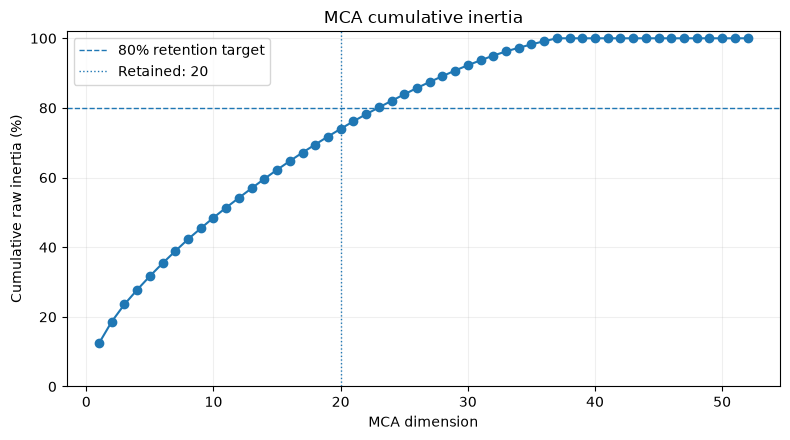

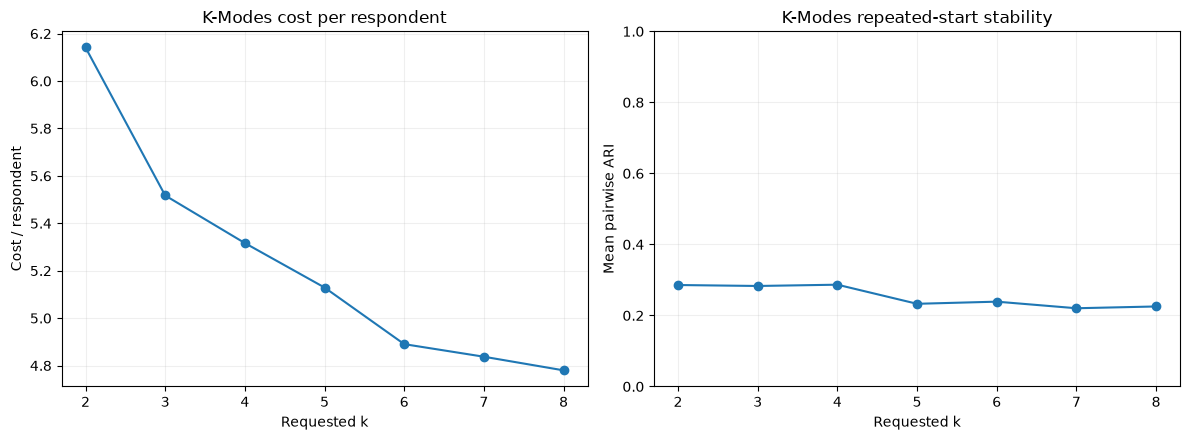

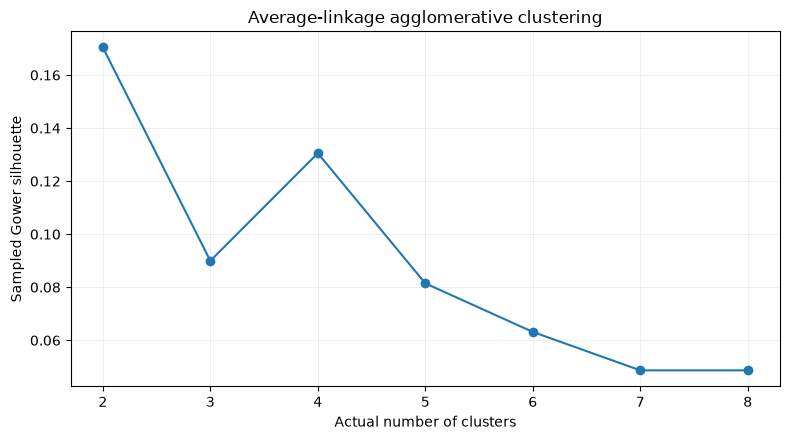

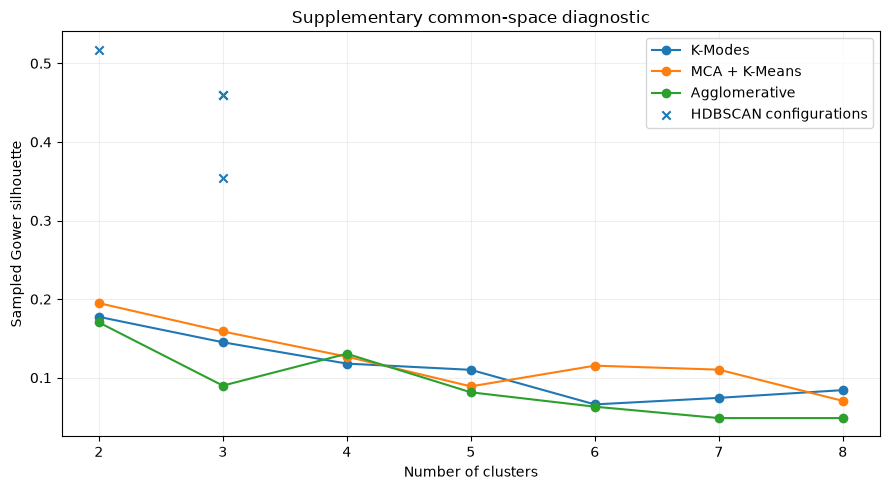

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mca_inertia["dimension"], mca_inertia["cumulative_inertia_pct"], marker="o")
ax.axhline(80, linestyle="--", linewidth=1, label="80% retention target")
ax.axvline(n_components, linestyle=":", linewidth=1, label=f"Retained: {n_components}")
ax.set(xlabel="MCA dimension", ylabel="Cumulative raw inertia (%)",
       title="MCA cumulative inertia")
ax.set_ylim(0, 102)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mca_cumulative_inertia.png", dpi=250, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(kmodes_results["k_requested"], kmodes_results["cost_per_respondent"], marker="o")
axes[0].set(title="K-Modes cost per respondent", xlabel="Requested k", ylabel="Cost / respondent")
axes[0].grid(alpha=0.2)
axes[1].plot(kmodes_results["k_requested"], kmodes_results["mean_pairwise_ari"], marker="o")
axes[1].set(title="K-Modes repeated-start stability", xlabel="Requested k", ylabel="Mean pairwise ARI")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kmodes_cost_stability.png", dpi=250, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(agglomerative_results["k_actual"], agglomerative_results["gower_silhouette"], marker="o")
ax.set(title="Average-linkage agglomerative clustering", xlabel="Actual number of clusters",
       ylabel="Sampled Gower silhouette")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "agglomerative_gower_silhouette.png", dpi=250, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for model_key, table, xcol in [
    ("K-Modes", kmodes_results, "k_requested"),
    ("MCA + K-Means", kmeans_results, "k_requested"),
    ("Agglomerative", agglomerative_results, "k_actual"),
]:
    ax.plot(table[xcol], table["gower_silhouette"], marker="o", label=model_key)
if not hdbscan_results.empty:
    ax.scatter(
        hdbscan_results["n_clusters"], hdbscan_results["gower_silhouette"],
        marker="x", label="HDBSCAN configurations",
    )
ax.set(title="Supplementary common-space diagnostic",
       xlabel="Number of clusters", ylabel="Sampled Gower silhouette")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "candidate_gower_silhouette.png", dpi=250, bbox_inches="tight")
plt.show()

## 13. Modelling conclusion and handoff to Notebook 04

In [28]:
handoff = {
    "prepared_respondents": EXPECTED_N,
    "primary_features": EXPECTED_P,
    "candidate_model_keys": list(candidate_label_sets),
    "representative_configurations": representatives,
    "overall_selection": "deferred_to_notebook_04",
    "candidate_labels_path": str(RESULTS_DIR / "osmi_2016_candidate_cluster_labels.csv"),
    "comparison_path": str(RESULTS_DIR / "osmi_2016_model_comparison.csv"),
}
display(pd.Series(handoff, name="Notebook 03 handoff"))

prepared_respondents                                                          1131
primary_features                                                                15
candidate_model_keys                       [K-Modes, MCA + K-Means, Agglomerative]
representative_configurations    {'K-Modes': {'k': 4, 'seed': 4048, 'selection_...
overall_selection                                          deferred_to_notebook_04
candidate_labels_path            C:\Users\User\Documents\Projects\osmi-mental-h...
comparison_path                  C:\Users\User\Documents\Projects\osmi-mental-h...
Name: Notebook 03 handoff, dtype: object